# 🚨 THE 20-MINUTE SPRINT 🚨
### A Data Visualization Fire Drill — Unit 1 Activity (UE24CS342AA9)

---

**08:47 AM.** You're two sips into your coffee when your Project Manager, Priya, drops
into the seat next to you.

> *"Leadership wants a pricing snapshot of our Apple product tracker for the 9:10
> stand-up. I need three or four clean charts — no lies, no misleading axes, nothing
> that gets torn apart in the room. You've got until 9:07. Go."*

It's **9:07 AM**. That's **20 minutes**, starting now.

You have one dataset (`apple_products_pricing_2020_2026.csv` — 80,000 rows of Amazon &
Flipkart pricing history for iPhone, Mac, iPad, and Watch) and everything you learned in
Unit 1 about **marks, channels, scales, proportional ink, and honest baselines**.

Leadership has seen bad charts before. They will notice a truncated bar axis. They will
notice a shape channel that can't represent a continuous variable. **Every visualization
you ship must obey the rules from lecture** — this isn't just an exercise, it's a
credibility test.

---

### 🎯 Mission Rules
1. Work through **Tasks 1–4** below, in order. Each has a suggested time box — keep moving.
2. Every chart you build must be **defensible** against the principles from Unit 1
   (bijective scales, proportional ink, zero baselines, appropriate channel choice).
3. At **Task 5**, do the honest self-audit before you "submit."
4. Finish with the **Reflection** section — that's where the real grade lives.

Ready? Run the setup cell and **start your timer**.


In [3]:
# --- MISSION SETUP: run this first, then start your 20-minute timer ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

df = pd.read_csv("apple_products_pricing_2020_2026 (1).csv", parse_dates=["Date"])

mission_start = time.time()
print("⏱️  MISSION CLOCK STARTED.")
print(f"Loaded {len(df):,} rows. You have 20 minutes. Go.")


⏱️  MISSION CLOCK STARTED.
Loaded 80,000 rows. You have 20 minutes. Go.


In [11]:
# Run this cell any time to check your remaining budget
elapsed_min = (time.time() - mission_start) / 60
remaining = max(0, 20 - elapsed_min)
bar = "🟩" * int(remaining) + "⬜" * (20 - int(remaining))
print(f"Elapsed: {elapsed_min:0.1f} min   |   Remaining: {remaining:0.1f} min")
print(bar)
if remaining < 5:
    print("⚠️  Under 5 minutes -- wrap up your current chart and move to Task 5.")


Elapsed: 3.7 min   |   Remaining: 16.3 min
🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩⬜⬜⬜⬜


---
## Task 1 — Know Your Variables *(~3 min)*

Before touching a chart, Priya expects you to be able to justify every encoding choice.
Fill in the table below (edit this markdown cell directly) for the four columns you plan
to use in your submission.

| Column you'll use | Variable type (continuous / discrete quantitative / ordered / unordered qualitative) | Channel you plan to map it to |
|---|---|---|
| *e.g. Current_Price_USD* | *e.g. Continuous quantitative* | *e.g. y-position* |
| Product_Category | Unordered qualitative | Color |
| Date | Continuous (temporal) | x-position |
| Rating | Discrete quantitative / Ordered qualitative | x-position |
| Reviews_Count | Discrete quantitative | Size |

**Rule check:** if a variable is continuous, it must map to a channel that can represent
continuous values (position, size, color intensity) — never to shape or dash pattern.


In [5]:
print("Column-by-column classification:")
classification = {
    "Date":               "Continuous (temporal)",
    "Product_Category":   "Unordered qualitative (categorical)",
    "Rating":             "Discrete quantitative / Ordered qualitative",
    "Reviews_Count":      "Discrete quantitative",
}
for col, kind in classification.items():
    print(f"  {col:20s} -> {kind}")

Column-by-column classification:
  Date                 -> Continuous (temporal)
  Product_Category     -> Unordered qualitative (categorical)
  Rating               -> Discrete quantitative / Ordered qualitative
  Reviews_Count        -> Discrete quantitative


---
## Task 2 — The Headline Bar Chart *(~5 min)*

Leadership always looks at the bar chart first. Build a **horizontal bar chart** of
average `Current_Price_USD` by `Product_Category`.

**Non-negotiable:** the baseline must be zero. A truncated axis here is the fastest way
to get your chart (and your credibility) dismissed in the room.

Fill in the `# TODO` lines below.


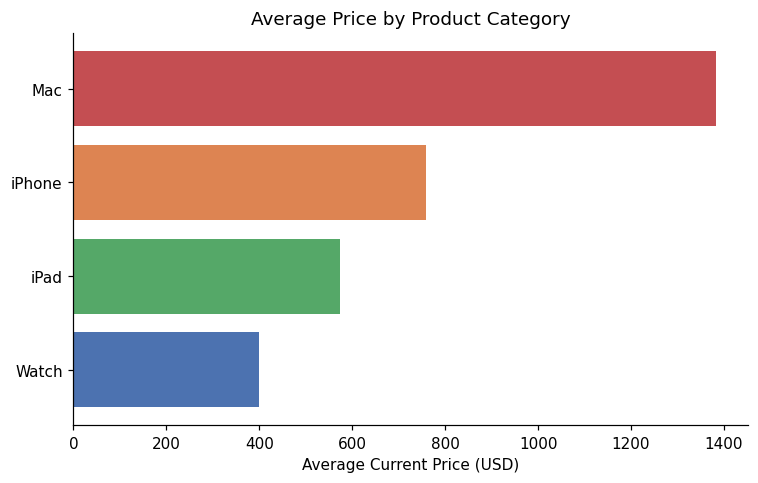

In [6]:
# TODO: compute average Current_Price_USD grouped by Product_Category, sorted ascending
cat_avg = df.groupby("Product_Category")["Current_Price_USD"].mean().sort_values()  # TODO: is this the right column/agg?

cat_color = {"iPhone": "#DD8452", "Mac": "#C44E52", "Watch": "#4C72B0", "iPad": "#55A868"}

fig, ax = plt.subplots(figsize=(7, 4.5))

# TODO: plot a horizontal bar chart (ax.barh) using cat_avg
bar_colors = [cat_color[cat] for cat in cat_avg.index]
ax.barh(cat_avg.index, cat_avg.values, color=bar_colors)

# TODO: enforce the zero-baseline rule -- do NOT delete this line
ax.set_xlim(left=0)

ax.set_xlabel("Average Current Price (USD)")
ax.set_title("Average Price by Product Category")
plt.tight_layout()
plt.show()


---
## Task 3 — The Trend Line, Done Right *(~5 min)*

Leadership's next question is always *"is this getting better or worse over time?"*
Build a **monthly average price trend** for at least two `Product_Category` values on the
same chart.

**Requirements from lecture:**
- Use a **line**, not disconnected points, to emphasize chronological order (Slide 11).
- Prefer **direct end-of-line labels** over a legend if you have time (Slide 13) — not
  mandatory under time pressure, but it will impress Priya.
- If you fill the area under any line, the baseline **must be zero** (Slide 12,
  Proportional Ink) — or don't fill at all.


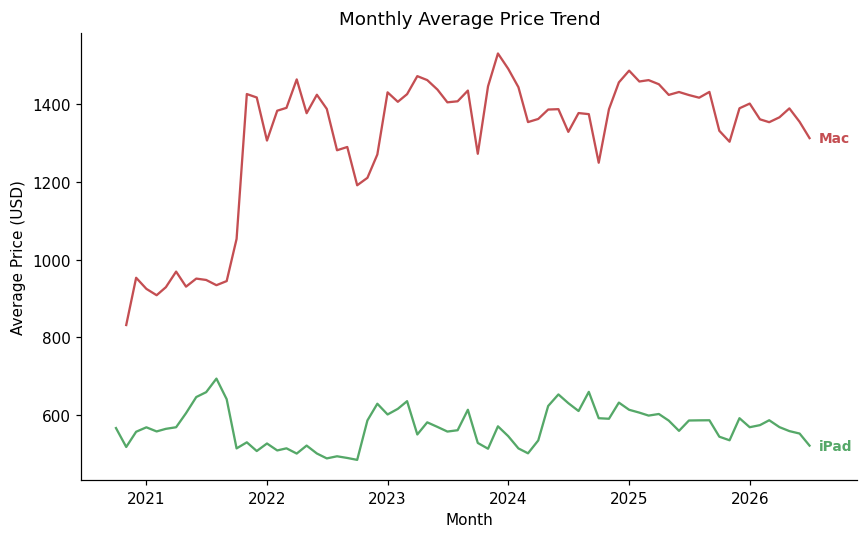

In [7]:
# TODO: pick 2+ categories to compare
categories_to_plot = ["iPad", "Mac"]  # TODO: feel free to change this list

cat_color = {"iPhone": "#DD8452", "Mac": "#C44E52", "Watch": "#4C72B0", "iPad": "#55A868"}

fig, ax = plt.subplots(figsize=(8, 5))

for cat in categories_to_plot:
    # TODO: resample monthly average price for this category
    monthly = (df[df["Product_Category"] == cat]
               .set_index("Date")
               .resample("MS")["Current_Price_USD"]
               .mean())
    line, = ax.plot(monthly.index, monthly.values, linewidth=1.5, label=cat, color=cat_color[cat])

    # TODO (optional, stretch goal): replace ax.legend() with direct end labels
    last_date, last_price = monthly.index[-1], monthly.values[-1]
    ax.annotate(cat, (last_date, last_price), textcoords="offset points", xytext=(6, 0), color=line.get_color(), fontsize=9, fontweight="bold", va="center")

ax.set_xlim(ax.get_xlim()[0], ax.get_xlim()[1] + 40)
ax.set_xlabel("Month")
ax.set_ylabel("Average Price (USD)")
ax.set_title("Monthly Average Price Trend")
plt.tight_layout()
plt.show()

---
## Task 4 — The "Wow" Multi-Variable Chart *(~5 min)*

Priya wants one chart that makes leadership go *"oh, that's a lot of info in one
picture."* Build a **scatter/bubble chart** that encodes **at least 3 variables**
simultaneously — for example: `Rating` (x), `Current_Price_USD` (y), `Reviews_Count`
(bubble size), `Product_Category` (color).

**Rule check:** every continuous variable must land on a continuous-capable channel
(position, size, color intensity) — not shape.


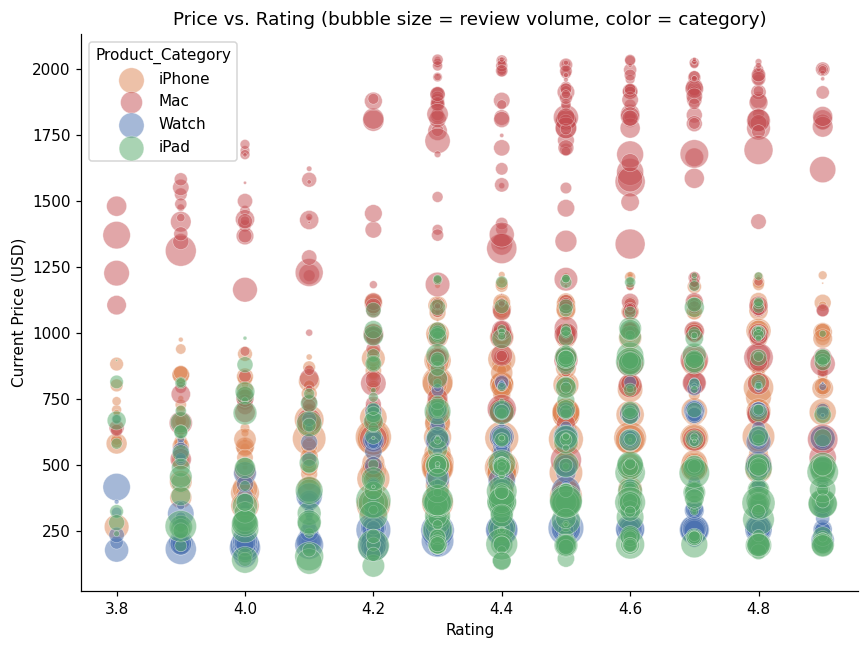

In [8]:
# TODO: build your 3+ variable bubble chart here
sample = df.sample(2000, random_state=1)

cat_color = {"iPhone": "#DD8452", "Mac": "#C44E52", "Watch": "#4C72B0", "iPad": "#55A868"}

fig, ax = plt.subplots(figsize=(8, 6))
for cat, color in cat_color.items():
    d = sample[sample["Product_Category"] == cat]
    ax.scatter(
        d["Rating"],                       # TODO: x axis has rating
        d["Current_Price_USD"],            # TODO: y axis has price
        s=d["Reviews_Count"] / 20,         # TODO: size = review volume (continuous -> size, good)
        color=color,                       # category -> color, good (categorical channel)
        alpha=0.5, edgecolor="white", linewidth=0.4, label=cat
    )

ax.set_xlabel("Rating")
ax.set_ylabel("Current Price (USD)")
ax.set_title("Price vs. Rating (bubble size = review volume, color = category)")
ax.legend(title="Product_Category")
plt.tight_layout()
plt.show()


---
## Task 5 — The Submission Audit *(~2 min)*

The clock is almost out. Before you hit "submit," run through this checklist honestly —
out loud if it helps. Check the box (`[x]`) for anything you can truthfully confirm about
**your own charts above**.

- [x] Every continuous variable is mapped to a continuous-capable channel (position,
      size, or color intensity) — not shape or dash pattern.
- [x] Every bar chart's axis starts at zero.
- [x] Every filled area chart's baseline starts at zero (or I didn't fill any areas).
- [x] My time-series uses lines to show chronological order, not disconnected points.
- [x] If two charts show the same variable, the colors/scales are used consistently.
- [x] I could explain, in one sentence, what each channel on each chart represents.

Run the cell below to log your finish time.


In [9]:
elapsed_min = (time.time() - mission_start) / 60
print(f"🏁 SUBMITTED at {elapsed_min:0.1f} minutes into the mission.")
if elapsed_min <= 20:
    print("✅ On time. Priya nods and walks it into the stand-up.")
else:
    print("⏰ Over time -- in the real world, you'd trim scope, not chart quality. Note this for your reflection.")


🏁 SUBMITTED at 0.0 minutes into the mission.
✅ On time. Priya nods and walks it into the stand-up.


---
## 🪞 Reflection

Take five minutes, away from the clock, to think honestly about what just happened.
Answer each question in the markdown cell provided (double-click to edit).

**1. Time pressure and technique.** Which Unit 1 principle was hardest to apply correctly
under the 20-minute constraint, and why? Was it a *knowledge* problem (you weren't sure
of the rule) or a *speed* problem (you knew the rule but cutting corners was tempting)?

*Your answer:*
I knew the zero-baseline rule and the shape-vs-color rule cold going in. What got me was keeping things consistent once I had three separate charts going. I built Task 2's bars, then Task 3's lines, then Task 4's bubbles, each one felt "done" on its own, but I wasn't checking them against each other as I went. That's more of a speed problem than a knowledge problem — I wasn't unsure of any rule, I just didn't compare the charts side by side until Task 5 asked me to.


---

**2. Spot the near-miss.** Look back at your own charts. Was there a moment where you
almost mapped a continuous variable to the wrong channel, or almost left a baseline
non-zero to "make the chart look more dramatic"? What stopped you (or what didn't)?

*Your answer:*
My Task 3 trend line didn't have a color set at first, so it just used whatever matplotlib's default colors were. When I compared it to my Task 4 bubble chart, I noticed the colour denotion wasn't consistent across the two charts. I only caught it because the last checklist made me actually look.

---

**3. The cost of dishonest ink.** Recall the Principle of Proportional Ink. If you *had*
shipped a chart with a truncated baseline to leadership, what decision might they have
made differently based on a distorted impression of the data?

*Your answer:*
If I'd truncated my Task 2 bar chart's x-axis instead of starting it at zero, Watch (cheapest category) would've looked almost as expensive as Mac (most expensive), because the visual length difference between the bars would shrink even though the real price gap didn't change. The users of the report/chart won't go into details, they read length, not the axis numbers. That could have lead them to think two product lines are priced closer together than they actually are.

---

**4. Trade-offs under constraint.** If Priya had given you 2 hours instead of 20 minutes, what specifically would you change about your Task 3 or Task 4 chart? (e.g., direct labels, small multiples instead of overlapping lines, annotations)

*Your answer:*
With more time I'd set up my cat_color dictionary once at the top before building any chart, instead of defining it in Task 4 and then having to go back and change Task 2 and Task 3 to match. I'd also look more carefully at whether plotting Rating on a continuous x-axis in Task 4 really makes sense — it turns out there are only 12 distinct rating values in the whole dataset, so it's more of a discrete variable than I treated it as. Small multiples per rating bucket might actually show the pattern more clearly than cramming everything onto one continuous axis.

---

**5. Beyond the classroom.** Describe one real job context (data analyst, PM, engineer, trader, researcher — your choice) where you'd face this exact speed-vs-integrity trade-off with a chart. What would *you* refuse to compromise on, even under a deadline?

*Your answer:*
I think about this like a data analyst prepping a dashboard for a exec review. If my manager asked me to truncate an axis "just to make the trend pop more" before a big meeting, I'd push back, even under a deadline, because the whole reason people trust a chart is that they don't have to double check the axis labels.